In [9]:
import pandas as pd

claims_df = pd.read_csv("claims.csv", encoding ="utf-8")
claims_df


,claim_id,policy_id,member_name,claim_type,diagnosis_icd10,submitted_amount,approved_amount,status,submitted_date,processed_date,assessor,insurer,country
0,CLM-10000,POL-30388,Mei Ho,OUTPATIENT,N39.0,5003,5003,APPROVED,2024-04-19,2024-05-05,Marcus Chen,Prudential Asia,Thailand
1,CLM-10001,POL-20094,Thuy Cheung,OUTPATIENT,N39.0,3003,2801,APPROVED,2024-10-03,2024-10-09,Marcus Chen,Prudential Asia,Hong Kong
2,CLM-10002,POL-25561,Naree Phan,INPATIENT,M54.5,56604,56604,APPROVED,2024-05-09,2024-05-16,Hong Pham,AIA Group,Hong Kong
3,CLM-10003,POL-19690,Chen Yip,OUTPATIENT,I10,1658,1031,APPROVED,2024-10-27,2024-11-03,Marcus Chen,Manulife Pacific,Hong Kong
4,CLM-10004,POL-12977,Chen Suriyawong,OUTPATIENT,E11.9,524,322,APPROVED,2024-03-18,2024-03-29,Daniel Tran,Prudential Asia,Thailand
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,CLM-14995,POL-20092,Somchai Dang,OUTPATIENT,J18.9,2001,2001,APPROVED,2024-01-05,2024-01-13,Daniel Tran,Manulife Pacific,Vietnam
4996,CLM-14996,POL-29782,Linh Ngo,INPATIENT,S93.4,98386,0,REJECTED,2024-05-03,2024-05-08,Marcus Chen,Prudential Asia,Hong Kong
4997,CLM-14997,POL-20040,Sarah Ngo,DENTAL,L03.90,2097,2097,APPROVED,2024-03-29,2024-04-03,Marcus Chen,Prudential Asia,Thailand
4998,CLM-14998,POL-47662,Ploy Suriyawong,OUTPATIENT,E78.5,591,0,IN_REVIEW,2024-10-22,2024-11-01,Apinya Wong,AIA Group,Vietnam


In [2]:
claims_df.isna().sum()
claims_df.dtypes

claim_id              str
policy_id             str
member_name           str
claim_type            str
diagnosis_icd10       str
submitted_amount    int64
approved_amount     int64
status                str
submitted_date        str
processed_date        str
assessor              str
insurer               str
country               str
dtype: object

In [3]:
claims_df.columns

Index(['claim_id', 'policy_id', 'member_name', 'claim_type', 'diagnosis_icd10',
       'submitted_amount', 'approved_amount', 'status', 'submitted_date',
       'processed_date', 'assessor', 'insurer', 'country'],
      dtype='str')

In [5]:
claims_df.duplicated().sum()

np.int64(0)

In [ ]:
claims_df[claims_df["processed_date"].isna()]
# the NANs make sense becuase this amount of money was never approved and that status says pending

,claim_id,policy_id,member_name,claim_type,diagnosis_icd10,submitted_amount,approved_amount,status,submitted_date,processed_date,assessor,insurer,country
15,CLM-10015,POL-32374,Tran Ho,INPATIENT,F41.9,77474,0,PENDING,2024-01-16,NaN,Grace Lam,Manulife Pacific,Hong Kong
42,CLM-10042,POL-32451,Ka Saetang,DENTAL,N39.0,8499,0,PENDING,2024-01-01,NaN,Marcus Chen,Prudential Asia,Vietnam
45,CLM-10045,POL-40732,Quang Cheung,MATERNITY,J18.9,54992,0,PENDING,2024-10-03,NaN,Apinya Wong,AIA Group,Thailand
47,CLM-10047,POL-36799,David Chaiyasit,DENTAL,S93.4,13019,0,PENDING,2024-04-25,NaN,Apinya Wong,Prudential Asia,Vietnam
67,CLM-10067,POL-37015,Wong Chan,OUTPATIENT,S93.4,4953,0,PENDING,2024-03-22,NaN,Hong Pham,Manulife Pacific,Hong Kong
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4974,CLM-14974,POL-32668,Le Lam,DENTAL,L03.90,6644,0,PENDING,2024-10-31,NaN,Grace Lam,Manulife Pacific,Hong Kong
4986,CLM-14986,POL-30139,Hui Bui,OUTPATIENT,E11.9,868,0,PENDING,2024-08-06,NaN,Hong Pham,AIA Group,Hong Kong
4990,CLM-14990,POL-23215,Somchai Pham,INPATIENT,E11.9,30795,0,PENDING,2024-05-26,NaN,Grace Lam,Prudential Asia,Vietnam
4994,CLM-14994,POL-20319,Hui Johnson,OUTPATIENT,G43.909,2236,0,PENDING,2024-07-23,NaN,Marcus Chen,Manulife Pacific,Vietnam


In [29]:
claims_df.groupby("claim_type")["submitted_amount"].agg(["mean","median"])

,mean,median
claim_type,,
DENTAL,6125.249520,3993.0
INPATIENT,85980.824164,57385.0
MATERNITY,69620.004237,48043.0
OUTPATIENT,3788.250603,2470.5


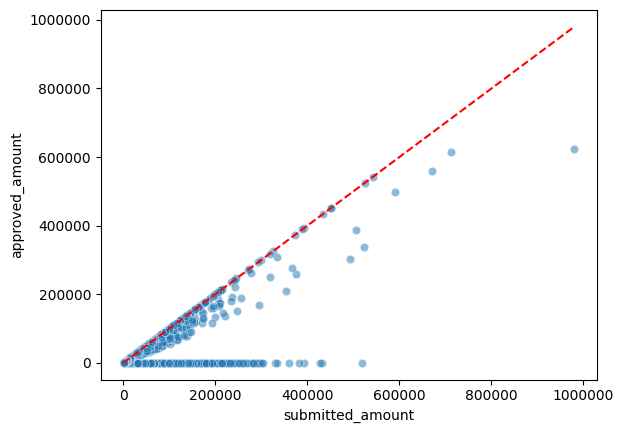

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=claims_df, x="submitted_amount", y="approved_amount", alpha = 0.5)
max_amount = claims_df[["submitted_amount", "approved_amount"]].max().max()
plt.plot([0, max_amount], [0, max_amount], "r--")
plt.ticklabel_format(style="plain", axis="both")
plt.show()

In [32]:
claims_df.groupby("claim_type")["status"].value_counts(normalize=True)*100

claim_type  status   
DENTAL      APPROVED     62.571977
            REJECTED     15.163148
            IN_REVIEW    11.708253
            PENDING      10.556622
INPATIENT   APPROVED     59.546926
            IN_REVIEW    14.455232
            REJECTED     13.915858
            PENDING      12.081985
MATERNITY   APPROVED     63.135593
            REJECTED     13.983051
            IN_REVIEW    12.288136
            PENDING      10.593220
OUTPATIENT  APPROVED     60.313631
            REJECTED     15.379976
            IN_REVIEW    13.148372
            PENDING      11.158022
Name: proportion, dtype: float64

<Axes: xlabel='claim_type', ylabel='proportion'>

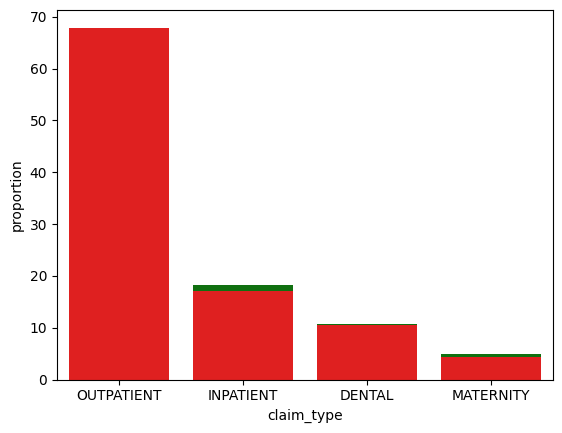

In [53]:
approved = claims_df[claims_df["status"]=="APPROVED"]["claim_type"].value_counts(normalize=True)*100
rejected = claims_df[claims_df["status"]=="REJECTED"]["claim_type"].value_counts(normalize=True)*100


sns.barplot(approved, color = "green")
sns.barplot(rejected, color="red")

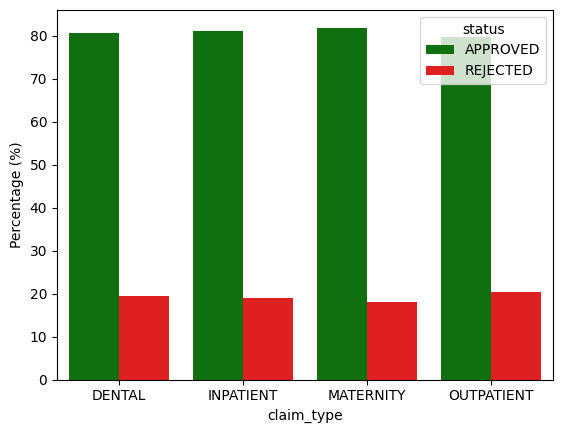

In [59]:
# Only consider resolved claims
resolved = claims_df[
    claims_df["status"].isin(["APPROVED", "REJECTED"])
]

# Calculate percentages by claim type
rates = (
    resolved.groupby("claim_type")["status"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("percentage")
    .reset_index()
)

# Plot
sns.barplot(
    data=rates,
    x="claim_type",
    y="percentage",
    hue="status",
    palette={"APPROVED": "green", "REJECTED": "red"}
)

plt.ylabel("Percentage (%)")
plt.show()

In [62]:
claims_df.groupby("claim_type")["submitted_amount"].agg(["mean","median"])

,mean,median
claim_type,,
DENTAL,6125.249520,3993.0
INPATIENT,85980.824164,57385.0
MATERNITY,69620.004237,48043.0
OUTPATIENT,3788.250603,2470.5


In [66]:
claims_df

,claim_id,policy_id,member_name,claim_type,diagnosis_icd10,submitted_amount,approved_amount,status,submitted_date,processed_date,assessor,insurer,country
0,CLM-10000,POL-30388,Mei Ho,OUTPATIENT,N39.0,5003,5003,APPROVED,2024-04-19,2024-05-05,Marcus Chen,Prudential Asia,Thailand
1,CLM-10001,POL-20094,Thuy Cheung,OUTPATIENT,N39.0,3003,2801,APPROVED,2024-10-03,2024-10-09,Marcus Chen,Prudential Asia,Hong Kong
2,CLM-10002,POL-25561,Naree Phan,INPATIENT,M54.5,56604,56604,APPROVED,2024-05-09,2024-05-16,Hong Pham,AIA Group,Hong Kong
3,CLM-10003,POL-19690,Chen Yip,OUTPATIENT,I10,1658,1031,APPROVED,2024-10-27,2024-11-03,Marcus Chen,Manulife Pacific,Hong Kong
4,CLM-10004,POL-12977,Chen Suriyawong,OUTPATIENT,E11.9,524,322,APPROVED,2024-03-18,2024-03-29,Daniel Tran,Prudential Asia,Thailand
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,CLM-14995,POL-20092,Somchai Dang,OUTPATIENT,J18.9,2001,2001,APPROVED,2024-01-05,2024-01-13,Daniel Tran,Manulife Pacific,Vietnam
4996,CLM-14996,POL-29782,Linh Ngo,INPATIENT,S93.4,98386,0,REJECTED,2024-05-03,2024-05-08,Marcus Chen,Prudential Asia,Hong Kong
4997,CLM-14997,POL-20040,Sarah Ngo,DENTAL,L03.90,2097,2097,APPROVED,2024-03-29,2024-04-03,Marcus Chen,Prudential Asia,Thailand
4998,CLM-14998,POL-47662,Ploy Suriyawong,OUTPATIENT,E78.5,591,0,IN_REVIEW,2024-10-22,2024-11-01,Apinya Wong,AIA Group,Vietnam


<Axes: xlabel='grouped'>

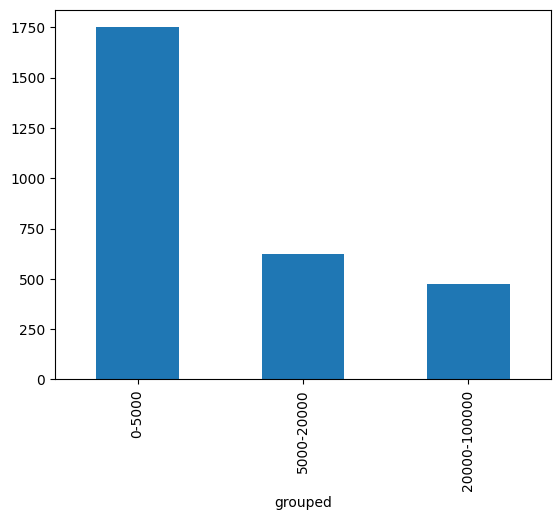

In [78]:
claims_df["grouped"] = pd.cut(claims_df["submitted_amount"], bins=[-1,5000,20000,100000], labels=("0-5000", "5000-20000", "20000-100000"))
claims_df[claims_df["status"]=="APPROVED"]["grouped"].value_counts().plot(kind="bar")

In [80]:
resolved = claims_df[
    claims_df["status"].isin(["APPROVED", "REJECTED"])
].copy()

# Group by submitted amount
resolved["grouped"] = pd.cut(
    resolved["submitted_amount"],
    bins=[0, 5000, 20000, 100000, float("inf")],
    labels=["0-5k", "5k-20k", "20k-100k", "100k+"],
    include_lowest=True
)
approval_rates = resolved.groupby("grouped", observed=True)["status"].apply(
    lambda x: (x == "APPROVED").mean() * 100)

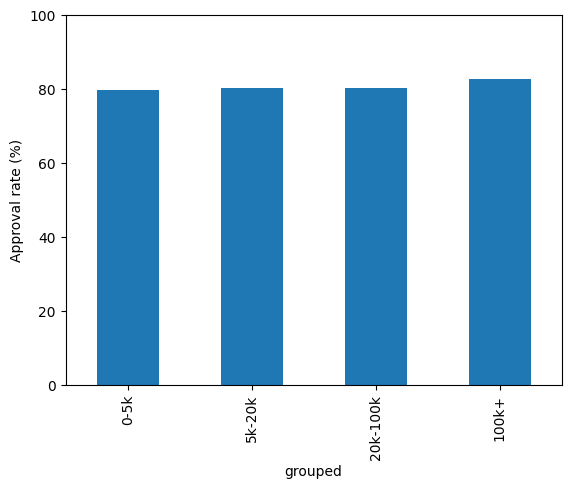

In [81]:
approval_rates.plot(kind="bar", ylabel="Approval rate (%)")
plt.ylim(0, 100)
plt.show()